<a href="https://colab.research.google.com/github/amrbensalah4-debug/ETRS923_IA/blob/main/TP1_MNIST/TP1_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
projet = '/content/drive/MyDrive/ETRS923/TP1_MNIST'
os.makedirs(projet + '/models', exist_ok=True)
os.chdir(projet)
print("Dossier de travail :", os.getcwd())

Mounted at /content/drive
Dossier de travail : /content/drive/MyDrive/ETRS923/TP1_MNIST


## Préparation : chargement de MNIST

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Images d'entraînement : (60000, 28, 28)
Images de test        : (10000, 28, 28)


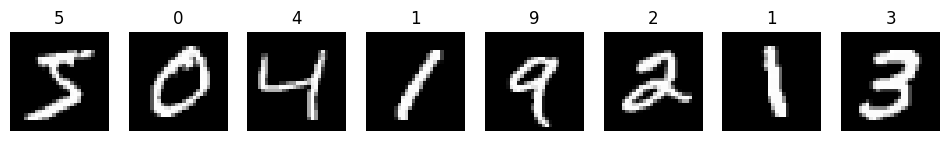

In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Charger MNIST (téléchargé automatiquement)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Images d'entraînement :", x_train.shape)
print("Images de test        :", x_test.shape)

# Afficher quelques exemples
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(y_train[i])
    ax.axis('off')
plt.show()

# Partie 1 : Choix de la fonction d'activation

Conditions imposées par le sujet :
- Optimiseur : **adam**
- Fonction coût : **categorical_crossentropy**

On compare plusieurs réseaux (softmax, ReLU, tanh, sigmoid) selon :
l'accuracy, le nombre d'epochs et le nombre de poids (synapses).

## Préparation des données (commune à toutes les questions)

Le réseau dense (MLP) ne lit pas une image en carré, il lit une ligne de nombres.
Il faut donc :
1. **Aplatir** chaque image 28×28 en un vecteur de 784 pixels.
2. **Normaliser** les pixels de [0, 255] vers [0, 1] : le réseau apprend mieux avec de petites valeurs.
3. **Encoder les réponses en one-hot** : le chiffre 5 devient [0,0,0,0,0,1,0,0,0,0].
   C'est le format attendu par categorical_crossentropy.

In [3]:
# ============================================================
# PRÉPARATION DES DONNÉES
# ============================================================

# --- 1. Aplatir les images : 28x28 -> 784 ---
# reshape(-1, 784) : "-1" laisse Python calculer le nombre d'images tout seul
# Résultat : un tableau de 60000 lignes (images) x 784 colonnes (pixels)
x_train_flat = x_train.reshape(-1, 784)
x_test_flat  = x_test.reshape(-1, 784)

# --- 2. Normaliser les pixels entre 0 et 1 ---
# Les pixels vont de 0 (noir) à 255 (blanc)
# astype('float32') : convertit en nombres à virgule (sinon la division ne marche pas bien)
# / 255 : ramène toutes les valeurs entre 0 et 1
x_train_flat = x_train_flat.astype('float32') / 255
x_test_flat  = x_test_flat.astype('float32') / 255

# --- 3. Encoder les réponses en one-hot ---
# Exigé par la fonction coût categorical_crossentropy
# Exemple : 5 -> [0,0,0,0,0,1,0,0,0,0]
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat  = keras.utils.to_categorical(y_test, 10)

# --- Vérifications ---
print("Forme des images d'entraînement :", x_train_flat.shape)   # attendu : (60000, 784)
print("Valeur max d'un pixel :", x_train_flat.max())             # attendu : 1.0
print("Réponse de la 1re image :", y_train[0], "->", y_train_cat[0])

# --- Tableau des résultats (rempli à chaque question, utilisé en 1.e) ---
resultats = []

Forme des images d'entraînement : (60000, 784)
Valeur max d'un pixel : 1.0
Réponse de la 1re image : 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Question 1.a : Réseau à deux couches avec softmax

Architecture : 784 (entrée) → 10 neurones (sortie, softmax)

- Aucune couche cachée : chaque neurone de sortie fait une somme pondérée des 784 pixels.
- **softmax** transforme les 10 sorties en probabilités dont la somme vaut 100 %.
- Le chiffre prédit est celui qui a la plus grande probabilité.

Nombre de poids attendu : 784 × 10 + 10 (biais) = **7 850**

In [4]:
# ============================================================
# QUESTION 1.a : Réseau softmax (784 -> 10)
# ============================================================

# --- 1. CONSTRUIRE le réseau ---
# Sequential : les couches s'enchaînent l'une après l'autre
model_softmax = keras.Sequential([
    keras.Input(shape=(784,)),                  # entrée : 784 pixels
    keras.layers.Dense(10, activation='softmax')  # sortie : 10 neurones (un par chiffre)
])
# "Dense" = chaque neurone est relié aux 784 pixels (couche entièrement connectée)

model_softmax.summary()   # affiche l'architecture et le nombre de poids

# --- 2. COMPILER : choisir comment le réseau apprend ---
model_softmax.compile(
    optimizer='adam',                     # méthode de correction des poids (imposée)
    loss='categorical_crossentropy',      # mesure de l'erreur (imposée, labels one-hot)
    metrics=['accuracy']                  # on veut suivre le % de bonnes réponses
)

# --- 3. ENTRAÎNER ---
historique_softmax = model_softmax.fit(
    x_train_flat, y_train_cat,
    epochs=10,              # 10 passages complets sur les 60 000 images
    batch_size=128,         # correction des poids tous les 128 images
    validation_split=0.1    # 10 % des images mises de côté pour surveiller l'apprentissage
)

# --- 4. TESTER sur les 10 000 images jamais vues ---
perte, precision = model_softmax.evaluate(x_test_flat, y_test_cat, verbose=0)
print(f"\nAccuracy sur le test : {precision*100:.2f} %")

# --- Enregistrer le résultat dans le tableau ---
resultats.append({
    'Question': '1.a',
    'Architecture': '784 → 10',
    'Activation': 'softmax',
    'Epochs': 10,
    'Nb de poids': model_softmax.count_params(),
    'Accuracy test (%)': round(precision*100, 2)
})

# --- Sauvegarder le modèle dans le Drive (utile pour le TP3) ---
model_softmax.save('models/mnist_softmax.keras')
print("Modèle sauvegardé dans models/")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8282 - loss: 0.7075 - val_accuracy: 0.9140 - val_loss: 0.3491
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8981 - loss: 0.3781 - val_accuracy: 0.9265 - val_loss: 0.2848
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9086 - loss: 0.3324 - val_accuracy: 0.9280 - val_loss: 0.2621
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9142 - loss: 0.3102 - val_accuracy: 0.9320 - val_loss: 0.2510
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9175 - loss: 0.2971 - val_accuracy: 0.9345 - val_loss: 0.2420
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9189 - loss: 0.2884 - val_accuracy: 0.9328 - val_loss: 0.2378
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9210 - loss: 0.2820 - val_accuracy: 0.9370 - val_loss: 0.2327
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9223 - loss: 0.2769 - val_accuracy: 0.

## Question 1.b : Réseau avec 2 couches cachées ReLU

Architecture : 784 → 128 (ReLU) → 64 (ReLU) → 10 (softmax)

- Les **couches cachées** permettent au réseau d'apprendre par étapes :
  petits motifs (traits, courbes), puis formes, puis chiffre.
- **ReLU** : si le score d'un neurone est négatif → 0, sinon on le garde.
  Cette non-linéarité est indispensable : sans elle, plusieurs couches
  équivaudraient à une seule.
- La sortie reste en **softmax** pour obtenir 10 probabilités.

Nombre de poids attendu : 100 480 + 8 256 + 650 = **109 386**

In [5]:
# ============================================================
# QUESTION 1.b : 2 couches cachées ReLU (784 -> 128 -> 64 -> 10)
# ============================================================

# --- 1. CONSTRUIRE le réseau ---
model_relu = keras.Sequential([
    keras.Input(shape=(784,)),                      # entrée : 784 pixels
    keras.layers.Dense(128, activation='relu'),     # 1re couche cachée : 128 neurones
    keras.layers.Dense(64,  activation='relu'),     # 2e couche cachée : 64 neurones
    keras.layers.Dense(10,  activation='softmax')   # sortie : 10 probabilités
])

model_relu.summary()   # vérifier : 109 386 paramètres

# --- 2. COMPILER (mêmes réglages qu'en 1.a, imposés par le sujet) ---
model_relu.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# --- 3. ENTRAÎNER (mêmes epochs et batch qu'en 1.a pour une comparaison juste) ---
historique_relu = model_relu.fit(
    x_train_flat, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

# --- 4. TESTER sur les 10 000 images jamais vues ---
perte, precision = model_relu.evaluate(x_test_flat, y_test_cat, verbose=0)
print(f"\nAccuracy sur le test : {precision*100:.2f} %")

# --- Enregistrer le résultat dans le tableau ---
resultats.append({
    'Question': '1.b',
    'Architecture': '784 → 128 → 64 → 10',
    'Activation': 'ReLU',
    'Epochs': 10,
    'Nb de poids': model_relu.count_params(),
    'Accuracy test (%)': round(precision*100, 2)
})

# --- Sauvegarder le modèle dans le Drive ---
model_relu.save('models/mnist_relu.keras')
print("Modèle sauvegardé dans models/")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.8953 - loss: 0.3655 - val_accuracy: 0.9558 - val_loss: 0.1595
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9540 - loss: 0.1545 - val_accuracy: 0.9685 - val_loss: 0.1093
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9684 - loss: 0.1076 - val_accuracy: 0.9682 - val_loss: 0.1040
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9761 - loss: 0.0805 - val_accuracy: 0.9760 - val_loss: 0.0867
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9810 - loss: 0.0636 - val_accuracy: 0.9758 - val_loss: 0.0889
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9846 - loss: 0.0519 - val_accuracy: 0.9762 - val_loss: 0.0818
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9872 - loss: 0.0429 - val_accuracy: 0.9728 - val_loss: 0.0911
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9896 - loss: 0.0338 - val_accuracy: 0.

## Question 1.c : Réseau avec 2 couches cachées tanh

Architecture : 784 → 128 (tanh) → 64 (tanh) → 10 (softmax)

- Même architecture et mêmes réglages qu'en 1.b : **seule la fonction d'activation change**,
  pour pouvoir comparer ReLU et tanh de façon équitable.
- **tanh** « écrase » le score de chaque neurone entre -1 et +1.
  Défaut : pour des scores très grands, la sortie reste bloquée à ±1
  et le neurone apprend lentement (**saturation**).
- La sortie reste en **softmax**.

Nombre de poids attendu : **109 386** (identique à 1.b, car l'activation n'ajoute aucun poids).

In [6]:
# ============================================================
# QUESTION 1.c : 2 couches cachées tanh (784 -> 128 -> 64 -> 10)
# ============================================================

# --- 1. CONSTRUIRE le réseau ---
# Même architecture que 1.b, seul 'relu' est remplacé par 'tanh'
model_tanh = keras.Sequential([
    keras.Input(shape=(784,)),                      # entrée : 784 pixels
    keras.layers.Dense(128, activation='tanh'),     # 1re couche cachée : 128 neurones
    keras.layers.Dense(64,  activation='tanh'),     # 2e couche cachée : 64 neurones
    keras.layers.Dense(10,  activation='softmax')   # sortie : 10 probabilités
])
model_tanh.summary()   # vérifier : 109 386 paramètres

# --- 2. COMPILER (réglages imposés par le sujet) ---
model_tanh.compile(
    optimizer='adam',                    # méthode de correction des poids
    loss='categorical_crossentropy',     # mesure de l'erreur (réponses en one-hot)
    metrics=['accuracy']                 # suivre le % de bonnes réponses
)

# --- 3. ENTRAÎNER (mêmes réglages qu'en 1.a et 1.b) ---
historique_tanh = model_tanh.fit(
    x_train_flat, y_train_cat,
    epochs=10,              # 10 passages sur toutes les images
    batch_size=128,         # correction des poids toutes les 128 images
    validation_split=0.1    # 10 % des images pour surveiller l'apprentissage
)

# --- 4. TESTER sur les 10 000 images jamais vues ---
perte, precision = model_tanh.evaluate(x_test_flat, y_test_cat, verbose=0)
print(f"\nAccuracy sur le test : {precision*100:.2f} %")

# --- 5. NOTER le résultat dans le tableau ---
resultats.append({
    'Question': '1.c',
    'Architecture': '784 → 128 → 64 → 10',
    'Activation': 'tanh',
    'Epochs': 10,
    'Nb de poids': model_tanh.count_params(),
    'Accuracy test (%)': round(precision*100, 2)
})

# --- 6. SAUVEGARDER dans le Drive ---
model_tanh.save('models/mnist_tanh.keras')
print("Modèle sauvegardé dans models/")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8947 - loss: 0.3712 - val_accuracy: 0.9487 - val_loss: 0.1821
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9487 - loss: 0.1774 - val_accuracy: 0.9662 - val_loss: 0.1259
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9627 - loss: 0.1261 - val_accuracy: 0.9688 - val_loss: 0.1069
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9718 - loss: 0.0958 - val_accuracy: 0.9745 - val_loss: 0.0914
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9781 - loss: 0.0743 - val_accuracy: 0.9760 - val_loss: 0.0783
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9830 - loss: 0.0590 - val_accuracy: 0.9767 - val_loss: 0.0813
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9857 - loss: 0.0479 - val_accuracy: 0.9787 - val_loss: 0.0774
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9892 - loss: 0.0378 - val_accuracy: 0.

## Question 1.d : Réseau avec 2 couches cachées sigmoid

Architecture : 784 → 128 (sigmoid) → 64 (sigmoid) → 10 (softmax)

- Même architecture et mêmes réglages qu'en 1.b et 1.c : **seule l'activation change**.
- **sigmoid** ramène le score de chaque neurone entre 0 et 1
  (0 = motif absent, 1 = motif présent).
- C'est la fonction historique des réseaux de neurones, mais elle **sature**
  encore plus que tanh : pour de grands scores, la sortie reste bloquée près de 1,
  le signal de correction devient très faible et l'apprentissage ralentit.

Nombre de poids attendu : **109 386**.

In [7]:
# ============================================================
# QUESTION 1.d : 2 couches cachées sigmoid (784 -> 128 -> 64 -> 10)
# ============================================================

# --- 1. CONSTRUIRE le réseau ---
# Même architecture que 1.b et 1.c, seule l'activation devient 'sigmoid'
model_sigmoid = keras.Sequential([
    keras.Input(shape=(784,)),                        # entrée : 784 pixels
    keras.layers.Dense(128, activation='sigmoid'),    # 1re couche cachée : 128 neurones
    keras.layers.Dense(64,  activation='sigmoid'),    # 2e couche cachée : 64 neurones
    keras.layers.Dense(10,  activation='softmax')     # sortie : 10 probabilités
])
model_sigmoid.summary()   # vérifier : 109 386 paramètres

# --- 2. COMPILER (réglages imposés par le sujet) ---
model_sigmoid.compile(
    optimizer='adam',                    # méthode de correction des poids
    loss='categorical_crossentropy',     # mesure de l'erreur
    metrics=['accuracy']                 # suivre le % de bonnes réponses
)

# --- 3. ENTRAÎNER (mêmes réglages que les autres questions) ---
historique_sigmoid = model_sigmoid.fit(
    x_train_flat, y_train_cat,
    epochs=10,              # 10 passages sur toutes les images
    batch_size=128,         # correction des poids toutes les 128 images
    validation_split=0.1    # 10 % des images pour surveiller l'apprentissage
)

# --- 4. TESTER sur les 10 000 images jamais vues ---
perte, precision = model_sigmoid.evaluate(x_test_flat, y_test_cat, verbose=0)
print(f"\nAccuracy sur le test : {precision*100:.2f} %")

# --- 5. NOTER le résultat dans le tableau ---
resultats.append({
    'Question': '1.d',
    'Architecture': '784 → 128 → 64 → 10',
    'Activation': 'sigmoid',
    'Epochs': 10,
    'Nb de poids': model_sigmoid.count_params(),
    'Accuracy test (%)': round(precision*100, 2)
})

# --- 6. SAUVEGARDER dans le Drive ---
model_sigmoid.save('models/mnist_sigmoid.keras')
print("Modèle sauvegardé dans models/")

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8131 - loss: 0.8256 - val_accuracy: 0.9275 - val_loss: 0.2938
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9221 - loss: 0.2824 - val_accuracy: 0.9477 - val_loss: 0.1921
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9401 - loss: 0.2098 - val_accuracy: 0.9585 - val_loss: 0.1566
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9514 - loss: 0.1686 - val_accuracy: 0.9632 - val_loss: 0.1343
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9589 - loss: 0.1402 - val_accuracy: 0.9668 - val_loss: 0.1186
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9657 - loss: 0.1182 - val_accuracy: 0.9712 - val_loss: 0.1041
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9709 - loss: 0.1009 - val_accuracy: 0.9723 - val_loss: 0.0969
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9754 - loss: 0.0862 - val_accuracy: 0.

## Question 1.e : Comparaison des implémentations

On compare les 4 réseaux selon :
- **l'accuracy** sur les 10 000 images de test,
- **le nombre d'epochs** nécessaires pour bien apprendre,
- **le nombre de poids** (taille de W stockée en mémoire, important pour la carte STM32).

In [8]:
# ============================================================
# QUESTION 1.e : Tableau comparatif
# ============================================================
import pandas as pd   # outil pour faire de jolis tableaux

# Transformer la liste "resultats" en tableau
tableau = pd.DataFrame(resultats)

# Ajouter la mémoire occupée : chaque poids = 4 octets en float32
tableau['Mémoire (Ko)'] = (tableau['Nb de poids'] * 4 / 1024).round(1)

# Si une question a été exécutée plusieurs fois, garder seulement le dernier essai
tableau = tableau.drop_duplicates(subset='Question', keep='last')

display(tableau)   # afficher le tableau

,Question,Architecture,Activation,Epochs,Nb de poids,Accuracy test (%),Mémoire (Ko)
0,1.a,784 → 10,softmax,10,7850,92.47,30.7
1,1.b,784 → 128 → 64 → 10,ReLU,10,109386,97.62,427.3
2,1.c,784 → 128 → 64 → 10,tanh,10,109386,97.69,427.3
3,1.d,784 → 128 → 64 → 10,sigmoid,10,109386,97.28,427.3


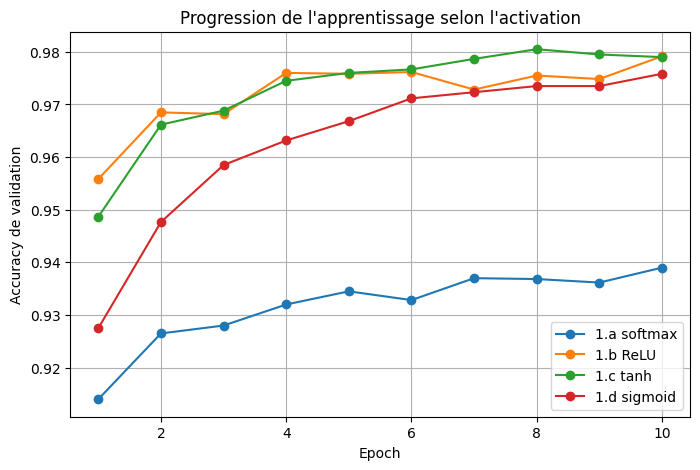

In [9]:
# ============================================================
# QUESTION 1.e : Courbes d'apprentissage (accuracy de validation par epoch)
# ============================================================

# On regroupe les historiques d'entraînement des 4 réseaux
historiques = {
    '1.a softmax': historique_softmax,
    '1.b ReLU':    historique_relu,
    '1.c tanh':    historique_tanh,
    '1.d sigmoid': historique_sigmoid,
}

plt.figure(figsize=(8, 5))
for nom, hist in historiques.items():
    # hist.history['val_accuracy'] = accuracy de validation à chaque epoch
    epochs = range(1, len(hist.history['val_accuracy']) + 1)
    plt.plot(epochs, hist.history['val_accuracy'], marker='o', label=nom)

plt.xlabel('Epoch')
plt.ylabel('Accuracy de validation')
plt.title("Progression de l'apprentissage selon l'activation")
plt.legend()
plt.grid(True)
plt.show()

### Analyse des résultats (1.e)

**1. Accuracy**
- Le réseau sans couche cachée (1.a, softmax) plafonne à **92,5 %** : une seule somme
  pondérée des pixels ne suffit pas à distinguer des chiffres écrits de façons différentes.
- Ajouter 2 couches cachées fait gagner **≈ 5 points** (97,3 à 97,7 %) : le réseau apprend
  par étapes (traits → formes → chiffre). Les erreurs sont divisées par environ 3.
- **ReLU (97,62 %) et tanh (97,69 %) sont équivalents** : l'écart (≈ 0,1 %) est du même ordre
  que la variation observée entre deux entraînements identiques (ReLU : 97,58 % puis 97,62 %).
- **sigmoid est légèrement en dessous (97,28 %)** avec 10 epochs.

**2. Nombre d'epochs (vitesse d'apprentissage)**
- D'après les courbes, **ReLU converge le plus vite** (95,6 % dès l'epoch 1), suivi de tanh.
- **sigmoid démarre plus lentement** (92,8 % à l'epoch 1) à cause de la **saturation** :
  pour de grands scores, sa sortie reste bloquée près de 1 et le signal de correction devient faible.
  Sa val_loss diminuait encore à l'epoch 10 : avec plus d'epochs, elle rattraperait probablement les autres.
- Pour ReLU, la val_loss remonte en fin d'entraînement (0,072 → 0,092) alors que l'accuracy
  d'entraînement atteint 99,4 % : début de **surapprentissage**. 6 à 8 epochs suffiraient.

**3. Nombre de poids et mémoire**
- 1.a : **7 850 poids (30,7 Ko)** ; 1.b/c/d : **109 386 poids (427,3 Ko)**, soit **14× plus**.
- La fonction d'activation **n'ajoute aucun poids** : seule l'architecture détermine la mémoire.
- Sur une STM32F446RE (128 Ko de RAM, 512 Ko de Flash), les 427 Ko en float32 occuperaient
  presque toute la Flash. Une **quantification en int8** (1 octet par poids au lieu de 4)
  ramènerait le modèle à ≈ 107 Ko.

**4. Conclusion : quel compromis ?**
- **Meilleur compromis précision / vitesse d'apprentissage : ReLU.** C'est aussi la plus simple
  à calculer sur microcontrôleur (une simple comparaison à 0, alors que tanh et sigmoid demandent
  des exponentielles).
- **Si la mémoire est la contrainte principale : le réseau 1.a** (14× plus léger, mais 5 points
  de précision en moins).
- **→ Architecture retenue pour la Partie 2 : 784 → 128 → 64 → 10 avec ReLU.**